## 1. Data Collection

This stage installs dependencies, defines the universe of technology-sector tickers,
and pulls raw historical price and dividend data from Yahoo Finance for each company.

### Installing Required Libraries

Install all packages needed for data collection, modelling, class-imbalance handling,
and interpretability. `imbalanced-learn` is required for SMOTE-based resampling used
later in the pipeline and must be included here to avoid an import failure in a
fresh environment.

In [ ]:
!pip install yfinance pandas numpy scikit-learn shap matplotlib seaborn joblib imbalanced-learn


Imported all libraries used across the notebook: data retrieval (`yfinance`), data
handling (`pandas`, `numpy`), class-imbalance handling (`imblearn`/SMOTE), modelling
and evaluation (`scikit-learn` — classifiers, CV/search tools, and metrics),
interpretability (`shap`), model persistence (`joblib`), and visualisation
(`matplotlib`, `seaborn`).

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import shap
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    balanced_accuracy_score,
    roc_curve,
    roc_auc_score
)
from scipy.stats import randint, uniform, loguniform
from imblearn.pipeline import Pipeline as ImbPipeline
import shap
from sklearn.pipeline import Pipeline as SkPipeline



Defined the sample universe: 39 large-cap technology-sector companies, grouped
informally by sub-sector (core tech, software/cloud, semiconductor, hardware/systems,
and platforms) for reference. This is the full candidate list before any data
availability filtering is applied.

In [ ]:
tickers = [
    # Core
    "INTC","AAPL","MSFT","NVDA","AMD",
    "CSCO","IBM","ORCL","TXN","QCOM",
    "AVGO","ADBE","CRM","AMAT","MU",

    # Software / Cloud
    "NOW","PANW","SNPS","CDNS","WDAY",
    "FTNT","TEAM","ZS","OKTA","CRWD",

    # Semiconductor
    "LRCX","KLAC","NXPI","MCHP","MRVL",
    "SWKS","ADI","ON","TER",

    # Hardware / Systems
    "HPQ","DELL","HPE",

    # Platforms
    "META","GOOGL"
]
print(f"Total tickers in sample: {len(tickers)}")

Total tickers in sample: 39


For each ticker, fetched daily price and dividend history (2010–2024) from Yahoo
Finance and aggregated it to annual frequency (`resample("YE")` — year-end) for
High/Low/Close/Volume and total dividends paid.

Derived three market-based features per year: `Price_Momentum` and
`Volume_Momentum` (year-on-year percentage change) and `Price_Range_Ratio`
(High/Low spread). These served as proxy signals for a company's growth and
volatility, used in place of fundamental data.

Built the prediction target by shifting each company's dividend forward by one
year (T+1): `Target = 1` if next year's dividend exceeded this year's, else `0`.
This ensured the label always reflected a genuine future outcome relative to the
features used to predict it, avoiding lookahead bias.

Tracked any companies dropped or partially lost — due to missing price history,
NaN feature values (first year per company, before `pct_change()` had a prior
value to compare against), or no valid next-year dividend pairing at the T+1
shift step — in `dropped_log` for later reporting.

In [ ]:
start_date = "2010-01-01"
end_date = "2025-01-01"

all_data = []
dropped_log = {}

for ticker in tickers:
    stock = yf.Ticker(ticker)
    hist = stock.history(start=start_date, end=end_date)

    if hist.empty:
        dropped_log[ticker] = "No price data returned by Yahoo Finance"
        continue

    # Annual aggregation using entire year
    annual = pd.DataFrame()
    annual["High"] = hist["High"].resample("YE").max()
    annual["Low"] = hist["Low"].resample("YE").min()
    annual["Close"] = hist["Close"].resample("YE").last()
    annual["Volume"] = hist["Volume"].resample("YE").sum()
    annual["Year"] = annual.index.year

    dividends = stock.dividends.resample("YE").sum()
    dividends = dividends.to_frame(name="Dividend")
    dividends["Year"] = dividends.index.year

    df = pd.merge(annual, dividends, on="Year", how="left")


    df["Dividend"] = df["Dividend"].fillna(0)

    # Market-based proxy features
    df["Price_Momentum"] = df["Close"].pct_change()
    df["Price_Range_Ratio"] = df["High"] / df["Low"]
    df["Volume_Momentum"] = df["Volume"].pct_change()

    df["Ticker"] = ticker

    all_data.append(df[[
        "Ticker","Year",
        "Price_Momentum",
        "Price_Range_Ratio",
        "Volume_Momentum",
        "Dividend"
    ]])

    n_rows = len(df)
    # Dividend can no longer be NaN (zero-filled above) — only the
    # pct_change features can still be NaN (first year per company)
    n_nan = df[["Price_Momentum","Price_Range_Ratio","Volume_Momentum"]].isna().any(axis=1).sum()
    if n_nan > 0:
        dropped_log[ticker] = f"{n_nan} of {n_rows} rows dropped due to NaN"

data = pd.concat(all_data, ignore_index=True)
data = data.sort_values(["Year","Ticker"]).reset_index(drop=True)

# Genuine future prediction: shift dividend forward by one year per company
data["Next_Dividend"] = data.groupby("Ticker")["Dividend"].shift(-1)

rows_before_shift_dropna = data.groupby("Ticker").size()
rows_after_shift_dropna = data.dropna(subset=["Next_Dividend"]).groupby("Ticker").size()

for ticker in tickers:
    before = rows_before_shift_dropna.get(ticker, 0)
    after = rows_after_shift_dropna.get(ticker, 0)
    if before > 0 and after == 0:
        dropped_log[ticker] = (
            f"All {before} year(s) of data lost at the T+1 shift step "
            f"(no valid next-year dividend pairing -- insufficient trading history)"
        )
    elif ticker not in rows_before_shift_dropna.index and ticker not in dropped_log:
        dropped_log[ticker] = "No usable rows after feature computation (upstream data issue)"

data = data.dropna(subset=["Next_Dividend"])
data["Target"] = (data["Next_Dividend"] > data["Dividend"]).astype(int)
data = data.drop(columns=["Next_Dividend"])

## 2. Preprocessing

Reported the row and company counts prior to removing missing values, and
inspected how many rows per company still contained NaNs in the feature or
target columns at this stage. This provided a baseline for measuring attrition
before any rows were dropped.

In [ ]:
print(f"Rows before dropna: {len(data)}")
print(f"Companies before dropna: {data['Ticker'].nunique()}")

nan_by_ticker = data.groupby("Ticker")[["Price_Momentum","Price_Range_Ratio","Volume_Momentum","Target"]].apply(
    lambda g: g.isna().any(axis=1).sum()
)
nan_by_ticker = nan_by_ticker[nan_by_ticker > 0]
if len(nan_by_ticker) > 0:
    print("\nRows with NaN per company (before dropna):")
    print(nan_by_ticker.to_string())

Rows before dropna: 498
Companies before dropna: 39

Rows with NaN per company (before dropna):
Ticker
AAPL     1
ADBE     1
ADI      1
AMAT     1
AMD      1
AVGO     1
CDNS     1
CRM      1
CRWD     1
CSCO     1
DELL     1
FTNT     1
GOOGL    1
HPE      1
HPQ      1
IBM      1
INTC     1
KLAC     1
LRCX     1
MCHP     1
META     1
MRVL     1
MSFT     1
MU       1
NOW      1
NVDA     1
NXPI     1
OKTA     1
ON       1
ORCL     1
PANW     1
QCOM     1
SNPS     1
SWKS     1
TEAM     1
TER      1
TXN      1
WDAY     1
ZS       1


Dropped all rows with NaN values for feature or target, and casted Target as integer type creating the data_clean, the final modelling dataset used in every subsequent step.

In [ ]:
data_clean = data.dropna(subset=["Price_Momentum","Price_Range_Ratio","Volume_Momentum","Target"]).copy()
data_clean["Target"] = data_clean["Target"].astype(int)

Built a per-company attrition table comparing total rows, rows dropped for NaNs,
and clean rows remaining, to quantify exactly how much data each company lost
during preprocessing and classify companies as fully removed, partially reduced,
or unchanged.

In [ ]:
# Per-company attrition: consistent NaN count on the exported columns only
feature_cols = ["Price_Momentum","Price_Range_Ratio","Volume_Momentum"]
all_rows = data.groupby("Ticker").size().rename("Total_Rows")
nan_rows = data.groupby("Ticker")[feature_cols + ["Target"]].apply(
    lambda g: g.isna().any(axis=1).sum()
).rename("NaN_Rows")
clean_rows = data_clean.groupby("Ticker").size().rename("Clean_Rows")

attrition = pd.concat([all_rows, nan_rows, clean_rows], axis=1).fillna(0).astype(int)
attrition["Removed"] = attrition["Total_Rows"] - attrition["Clean_Rows"]
attrition = attrition.sort_values("Removed", ascending=False)

print("PER-COMPANY ATTRITION TABLE")
print("=" * 70)
print(attrition.to_string())
print(f"\nCompanies fully removed (0 clean rows): {(attrition['Clean_Rows'] == 0).sum()}")
print(f"Companies partially reduced: {((attrition['Clean_Rows'] > 0) & (attrition['Removed'] > 0)).sum()}")
print(f"Companies unchanged: {(attrition['Removed'] == 0).sum()}")

PER-COMPANY ATTRITION TABLE
        Total_Rows  NaN_Rows  Clean_Rows  Removed
Ticker                                           
AAPL            14         1          13        1
ADBE            14         1          13        1
ADI             14         1          13        1
AMAT            14         1          13        1
AMD             14         1          13        1
AVGO            14         1          13        1
CDNS            14         1          13        1
CRM             14         1          13        1
CRWD             5         1           4        1
CSCO            14         1          13        1
DELL             8         1           7        1
FTNT            14         1          13        1
GOOGL           14         1          13        1
HPE              9         1           8        1
HPQ             14         1          13        1
IBM             14         1          13        1
INTC            14         1          13        1
KLAC            14    

Summarised the final dataset: how many of the original 39 tickers survived
cleaning, and the resulting total observations, company count, and year range.

### Note on Date Range

Raw price and dividend data collection began on **1 January 2010**. However, the
final analytical dataset spans **2011–2023**, not 2010–2024, for two reasons:

- **2010 was dropped:** `Price_Momentum` and `Volume_Momentum` are year-on-year
  percentage changes (`pct_change()`), which require a prior year of data. Each
  company's first observation (2010) had no prior year to compare against, so it
  was `NaN` and removed.
- **2024 was dropped:** The target variable (`Next_Dividend`) was built by
  shifting each company's dividend series forward by one year (T+1). The most
  recent year available (2024) had no subsequent year's dividend to compare
  against, so its target was `NaN` and it was removed.

After these steps, the final dataset contained **459 observations from 39
companies**, covering **2011–2023**. No companies were removed during collection
(39 tickers in, 39 tickers out) — the reduction in usable rows came entirely from
the momentum and target construction described above, not from missing raw data.

In [ ]:
survived = sorted(data_clean["Ticker"].unique().tolist())
removed = sorted([t for t in tickers if t not in survived])

print(f"Total tickers:          {len(tickers)}")
print(f"Survived:               {len(survived)} companies")
print(f"Removed:                {len(removed)} companies — {removed}")
print(f"\nFinal dataset size:     {len(data_clean)} observations, {data_clean['Ticker'].nunique()} companies")
print(f"Year range:             {data_clean['Year'].min()} – {data_clean['Year'].max()}")
print(f"Avg obs per company:    {len(data_clean) / data_clean['Ticker'].nunique():.1f}")

Total tickers:          39
Survived:               39 companies
Removed:                0 companies — []

Final dataset size:     459 observations, 39 companies
Year range:             2011 – 2023
Avg obs per company:    11.8


Reported which companies (if any) were fully removed from the dataset and why
(from `dropped_log`), and which companies retained partial data with some years
lost. This confirmed that all 39 companies survived cleaning with no full or
partial data loss.

In [ ]:
# Fully removed companies
print("COMPANY REMOVAL SUMMARY")
print("=" * 60)
if len(removed) == 0:
    print(f"  No companies were fully removed. All {len(tickers)} survived dropna.")
else:
    for ticker in removed:
        reason = dropped_log.get(ticker, "No dividend data or insufficient history")
        print(f"  {ticker:6s} -> {reason}")

# Companies with partial data loss (lost some years but not all)
partial = attrition[(attrition["Clean_Rows"] > 0) & (attrition["Removed"] > 0)]
if len(partial) > 0:
    print(f"\nPARTIAL DATA LOSS ({len(partial)} companies lost rows):")
    print("=" * 60)
    for ticker, row in partial.iterrows():
        print(f"  {ticker:6s} -> {row['Total_Rows']} total, {row['NaN_Rows']} NaN, {row['Clean_Rows']} kept")
else:
    print("\nNo partial data loss — all companies retained the same number of rows.")

COMPANY REMOVAL SUMMARY
  No companies were fully removed. All 39 survived dropna.

PARTIAL DATA LOSS (39 companies lost rows):
  AAPL   -> 14 total, 1 NaN, 13 kept
  ADBE   -> 14 total, 1 NaN, 13 kept
  ADI    -> 14 total, 1 NaN, 13 kept
  AMAT   -> 14 total, 1 NaN, 13 kept
  AMD    -> 14 total, 1 NaN, 13 kept
  AVGO   -> 14 total, 1 NaN, 13 kept
  CDNS   -> 14 total, 1 NaN, 13 kept
  CRM    -> 14 total, 1 NaN, 13 kept
  CRWD   -> 5 total, 1 NaN, 4 kept
  CSCO   -> 14 total, 1 NaN, 13 kept
  DELL   -> 8 total, 1 NaN, 7 kept
  FTNT   -> 14 total, 1 NaN, 13 kept
  GOOGL  -> 14 total, 1 NaN, 13 kept
  HPE    -> 9 total, 1 NaN, 8 kept
  HPQ    -> 14 total, 1 NaN, 13 kept
  IBM    -> 14 total, 1 NaN, 13 kept
  INTC   -> 14 total, 1 NaN, 13 kept
  KLAC   -> 14 total, 1 NaN, 13 kept
  LRCX   -> 14 total, 1 NaN, 13 kept
  MCHP   -> 14 total, 1 NaN, 13 kept
  META   -> 12 total, 1 NaN, 11 kept
  MRVL   -> 14 total, 1 NaN, 13 kept
  MSFT   -> 14 total, 1 NaN, 13 kept
  MU     -> 14 total, 1 NaN

## 3. Exploratory Data Analysis

Examined the target class balance (dividend increase vs. no increase) and
confirmed a meaningful class imbalance. Noted that plain accuracy would be
misleading given the majority class baseline, and that SMOTE together with
balanced metrics (precision, recall, F1, balanced accuracy, confusion matrix)
was used later to address this.

In [ ]:
class_counts = data_clean["Target"].value_counts()
class_pct = data_clean["Target"].value_counts(normalize=True) * 100

majority_class = class_pct.idxmax()
majority_pct = class_pct.max()
majority_label = "Increase" if majority_class == 1 else "No Increase"

print("Target Class Distribution:")
print(f"  Dividend Increase (1): {class_counts.get(1, 0)} ({class_pct.get(1, 0):.1f}%)")
print(f"  No Increase      (0): {class_counts.get(0, 0)} ({class_pct.get(0, 0):.1f}%)")
print(f"  Imbalance ratio:       {class_counts[1]/class_counts[0]:.1f}:1")
print("\nNote: Basic accuracy would be misleading. A model predicting")
print(f"'{majority_label}' for every observation would achieve ~{majority_pct:.1f}% accuracy.")
print("To address this imbalance, the modelling notebook applies SMOTE")
print("(Synthetic Minority Over-sampling Technique) on the training set")
print("and reports precision, recall, F1, balanced accuracy, and confusion matrix.")

Target Class Distribution:
  Dividend Increase (1): 235 (51.2%)
  No Increase      (0): 224 (48.8%)
  Imbalance ratio:       1.0:1

Note: Basic accuracy would be misleading. A model predicting
'Increase' for every observation would achieve ~51.2% accuracy.
To address this imbalance, the modelling notebook applies SMOTE
(Synthetic Minority Over-sampling Technique) on the training set
and reports precision, recall, F1, balanced accuracy, and confusion matrix.


Counts of observations per year, per class for each target were calculated and plotted as a bar chart plotting the time-periods classes appeared through the period 2011–2023.

OBSERVATIONS PER YEAR
      No Increase (0)  Increase (1)
Year                               
2011               13            16
2012               14            15
2013               16            17
2014               17            16
2015               17            16
2016               17            18
2017               16            20
2018               19            18
2019               19            19
2020               21            18
2021               18            21
2022               20            19
2023               17            22

Total observations: 459


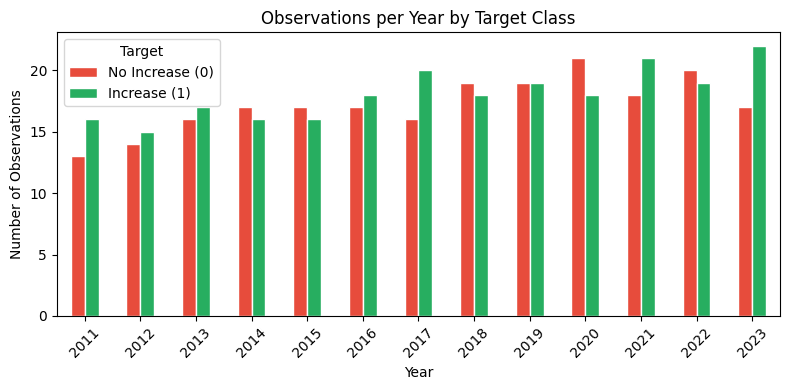

In [ ]:
# Per-year observation counts
year_counts = data_clean.groupby("Year").size()
year_class = data_clean.groupby(["Year", "Target"]).size().unstack(fill_value=0)
year_class.columns = ["No Increase (0)", "Increase (1)"]

print("OBSERVATIONS PER YEAR")
print("=" * 50)
print(year_class.to_string())
print(f"\nTotal observations: {len(data_clean)}")

# Bar chart
fig, ax = plt.subplots(figsize=(8, 4))
year_class.plot(kind="bar", ax=ax, color=["#e74c3c", "#27ae60"], edgecolor="white")
ax.set_title("Observations per Year by Target Class")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Observations")
ax.legend(title="Target")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Summarised each surviving company's coverage — first year, last year, and number
of observations — to confirm a consistent panel structure across all 39 firms.

In [ ]:
# Per-company summary: year range and observation count
company_summary = data_clean.groupby("Ticker").agg(
    First_Year=("Year", "min"),
    Last_Year=("Year", "max"),
    Observations=("Year", "size")
).sort_values("Ticker")

print("PER-COMPANY SUMMARY (surviving companies only)")
print("=" * 55)
print(company_summary.to_string())

PER-COMPANY SUMMARY (surviving companies only)
        First_Year  Last_Year  Observations
Ticker                                     
AAPL          2011       2023            13
ADBE          2011       2023            13
ADI           2011       2023            13
AMAT          2011       2023            13
AMD           2011       2023            13
AVGO          2011       2023            13
CDNS          2011       2023            13
CRM           2011       2023            13
CRWD          2020       2023             4
CSCO          2011       2023            13
DELL          2017       2023             7
FTNT          2011       2023            13
GOOGL         2011       2023            13
HPE           2016       2023             8
HPQ           2011       2023            13
IBM           2011       2023            13
INTC          2011       2023            13
KLAC          2011       2023            13
LRCX          2011       2023            13
MCHP          2011       2023

Exported the cleaned, final feature set to `dividend_dataset.csv` for
reproducibility and downstream use, confirming its shape (459 rows × 6 columns)
and column names.

In [ ]:

export_cols = ["Ticker", "Year", "Price_Momentum", "Price_Range_Ratio", "Volume_Momentum", "Target"]
data_clean[export_cols].to_csv("dividend_dataset.csv", index=False)

print("Dataset saved successfully as 'dividend_dataset.csv'")
print(f"  Shape: {data_clean[export_cols].shape}")
print(f"  Columns: {export_cols}")

Dataset saved successfully as 'dividend_dataset.csv'
  Shape: (459, 6)
  Columns: ['Ticker', 'Year', 'Price_Momentum', 'Price_Range_Ratio', 'Volume_Momentum', 'Target']


Printed dataset info (column types, non-null counts) and summary statistics
(mean, standard deviation, min/max, quartiles) for the engineered features and
target, as a final sanity check on the cleaned data.

In [ ]:
print("\nDataset Info:")
print(data_clean.info())

print("\nSummary Statistics:")
print(data_clean.describe())



Dataset Info:
<class 'pandas.core.frame.DataFrame'>
Index: 459 entries, 29 to 497
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Ticker             459 non-null    object 
 1   Year               459 non-null    int32  
 2   Price_Momentum     459 non-null    float64
 3   Price_Range_Ratio  459 non-null    float64
 4   Volume_Momentum    459 non-null    float64
 5   Dividend           459 non-null    float64
 6   Target             459 non-null    int64  
dtypes: float64(4), int32(1), int64(1), object(1)
memory usage: 26.9+ KB
None

Summary Statistics:
              Year  Price_Momentum  Price_Range_Ratio  Volume_Momentum  \
count   459.000000      459.000000         459.000000       459.000000   
mean   2017.357298        0.294806           1.836738         0.064413   
std       3.692730        0.500791           0.675572         0.638406   
min    2011.000000       -0.695187           1.204655     

Directly visualized target class distribution through a count plot, echoing the earlier numerical class imbalance analysis.


Class Distribution:
Target
1    235
0    224
Name: count, dtype: int64


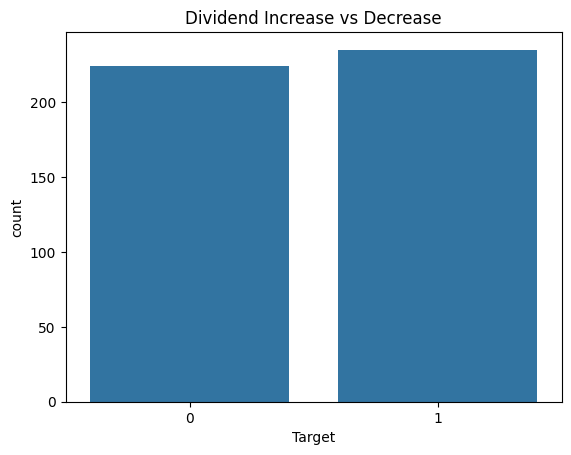

In [ ]:
print("\nClass Distribution:")
print(data_clean["Target"].value_counts())

sns.countplot(x="Target", data=data_clean)
plt.title("Dividend Increase vs Decrease")
plt.show()


Checked the shape of each feature ( Price_Momentum, Price_Range_Ratio, Volume_Momentum ) by plotting their distribution and checking for skew and outliers.

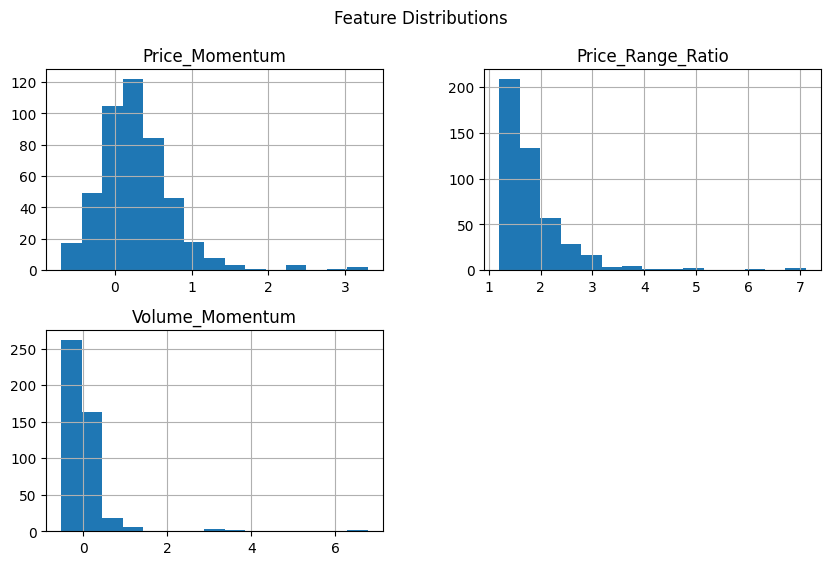

In [ ]:
data_clean[["Price_Momentum","Price_Range_Ratio","Volume_Momentum"]].hist(
    figsize=(10,6), bins=15
)
plt.suptitle("Feature Distributions")
plt.show()


Computed and visualised the correlation matrix between features and the target,
checking for multicollinearity between features and any obvious linear
relationship with the target.

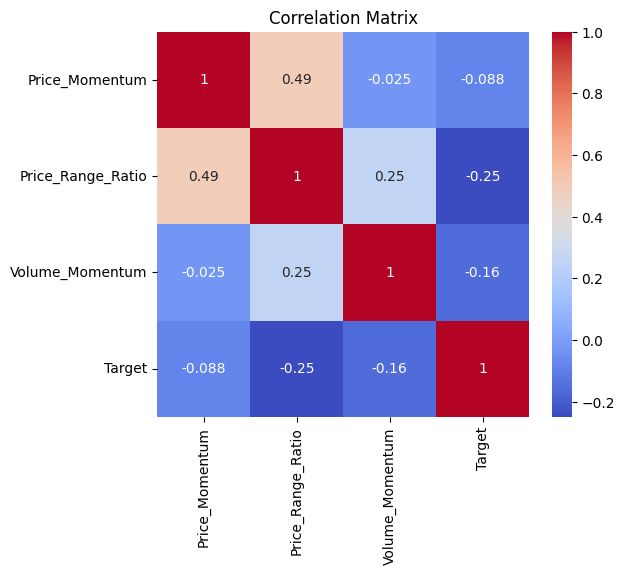

In [ ]:
plt.figure(figsize=(6,5))
sns.heatmap(
    data_clean[["Price_Momentum","Price_Range_Ratio","Volume_Momentum","Target"]].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Correlation Matrix")
plt.show()


## 4. Modelling

Split the data chronologically at the 75th percentile year — training on earlier
years and testing on later years — rather than a random split. This ensured the
test set represented genuinely unseen future years and avoided temporal data
leakage where future information could otherwise leak into training.

In [ ]:
features = ["Price_Momentum", "Price_Range_Ratio", "Volume_Momentum"]

# Time-based split: train on earlier years, test on later years
# This prevents temporal data leakage where future information leaks into training
split_year = data_clean["Year"].quantile(0.75)
print(f"Train/Test split year: {split_year:.0f}")
print(f"Train: Year <= {split_year:.0f}, Test: Year > {split_year:.0f}")

train_mask = data_clean["Year"] <= split_year
test_mask = data_clean["Year"] > split_year

X_train = data_clean.loc[train_mask, features]
y_train = data_clean.loc[train_mask, "Target"]
X_test = data_clean.loc[test_mask, features]
y_test = data_clean.loc[test_mask, "Target"]

print(f"\nTrain set: {len(X_train)} observations ({y_train.sum()} positive, {(y_train==0).sum()} negative)")
print(f"Test set:  {len(X_test)} observations ({y_test.sum()} positive, {(y_test==0).sum()} negative)")
print(f"Train year range: {data_clean.loc[train_mask, 'Year'].min()} - {data_clean.loc[train_mask, 'Year'].max()}")
print(f"Test year range:  {data_clean.loc[test_mask, 'Year'].min()} - {data_clean.loc[test_mask, 'Year'].max()}")


Train/Test split year: 2021
Train: Year <= 2021, Test: Year > 2021

Train set: 381 observations (194 positive, 187 negative)
Test set:  78 observations (41 positive, 37 negative)
Train year range: 2011 - 2021
Test year range:  2022 - 2023


Applied SMOTE to the training set only, generating synthetic minority-class
samples to fully balance `Target`. This balanced version (`X_train_bal`,
`y_train_bal`) was used only for the single-fit "default" baseline models and
the final refit of the chosen model — never for the cross-validated
hyperparameter search or CV scoring, since the `year_cv` fold indices are built
against the original (pre-SMOTE) row positions and would silently misalign
against the larger, resampled array. For those CV-based steps, SMOTE was instead
applied inside each fold via an `imblearn` pipeline.

In [ ]:
smote = SMOTE(random_state=42, k_neighbors=3, sampling_strategy=1.0)

X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print("\nBalanced Training Distribution:")
print(pd.Series(y_train_bal).value_counts())




Balanced Training Distribution:
Target
1    194
0    194
Name: count, dtype: int64


Fitted default (untuned) versions of all four candidate models — Random Forest,
Decision Tree, Gradient Boosting, and Logistic Regression — on the SMOTE-balanced
training data produced in the previous cell, to serve as baseline models before
hyperparameter tuning. All four were trained on raw (unscaled) features, so
downstream evaluation calls `.predict(X_test)` directly with no scaler needed.

In [ ]:
# =========================
# Random Forest (Default)
# =========================
default_rf = RandomForestClassifier(random_state=42)
default_rf.fit(X_train_bal, y_train_bal)

# =========================
# Decision Tree (Default)
# =========================
default_dt = DecisionTreeClassifier(random_state=42)
default_dt.fit(X_train_bal, y_train_bal)

# =========================
# Gradient Boosting (Default)
# =========================
default_gb = GradientBoostingClassifier(random_state=42)
default_gb.fit(X_train_bal, y_train_bal)

# =========================
# Logistic Regression (Default)
# =========================
default_lr = LogisticRegression(
    random_state=42,
    max_iter=1000,
    solver="lbfgs"
)
default_lr.fit(X_train_bal, y_train_bal)

# Store default models for later comparison
default_models = {
    "Random Forest (Default)": default_rf,
    "Decision Tree (Default)": default_dt,
    "Gradient Boosting (Default)": default_gb,
    "Logistic Regression (Default)": default_lr
}

# IMPORTANT: default models are trained on raw (unscaled) features
# via SMOTE-resampled X_train. Downstream cells call .predict(X_test)
# directly — no scaler needed.


Balanced Training Distribution (post-SMOTE):
Target
1    194
0    194
Name: count, dtype: int64


## 5. Evaluation

Evaluated the default (untuned) models on the held-out test set using accuracy,
balanced accuracy, ROC-AUC, and full classification reports, along with confusion
matrices for each model. Compiled the results into a single comparison table
as a baseline to measure the impact of hyperparameter tuning against.


Random Forest
Accuracy: 0.5641025641025641
Balanced Accuracy: 0.5655899802241267
AUC: 0.6519446275543836
              precision    recall  f1-score   support

           0       0.54      0.59      0.56        37
           1       0.59      0.54      0.56        41

    accuracy                           0.56        78
   macro avg       0.57      0.57      0.56        78
weighted avg       0.57      0.56      0.56        78



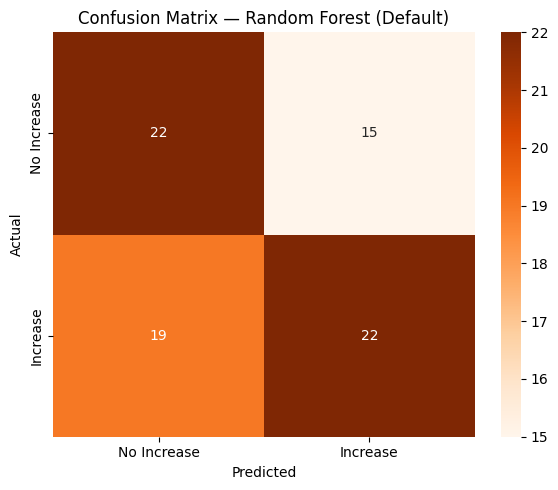


Decision Tree
Accuracy: 0.5256410256410257
Balanced Accuracy: 0.5210942649967041
AUC: 0.5210942649967041
              precision    recall  f1-score   support

           0       0.50      0.43      0.46        37
           1       0.54      0.61      0.57        41

    accuracy                           0.53        78
   macro avg       0.52      0.52      0.52        78
weighted avg       0.52      0.53      0.52        78



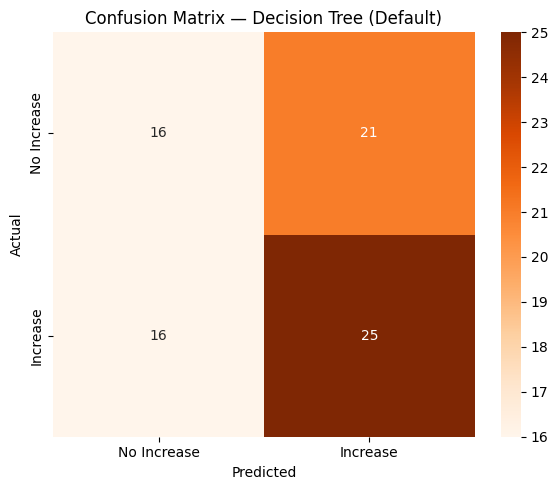


Gradient Boosting
Accuracy: 0.48717948717948717
Balanced Accuracy: 0.48319050758075155
AUC: 0.47132498352010543
              precision    recall  f1-score   support

           0       0.45      0.41      0.43        37
           1       0.51      0.56      0.53        41

    accuracy                           0.49        78
   macro avg       0.48      0.48      0.48        78
weighted avg       0.48      0.49      0.48        78



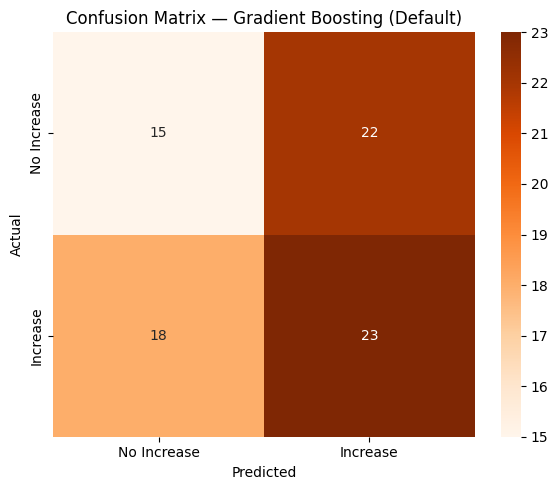


Logistic Regression
Accuracy: 0.717948717948718
Balanced Accuracy: 0.7172050098879368
AUC: 0.7949901120632828
              precision    recall  f1-score   support

           0       0.70      0.70      0.70        37
           1       0.73      0.73      0.73        41

    accuracy                           0.72        78
   macro avg       0.72      0.72      0.72        78
weighted avg       0.72      0.72      0.72        78



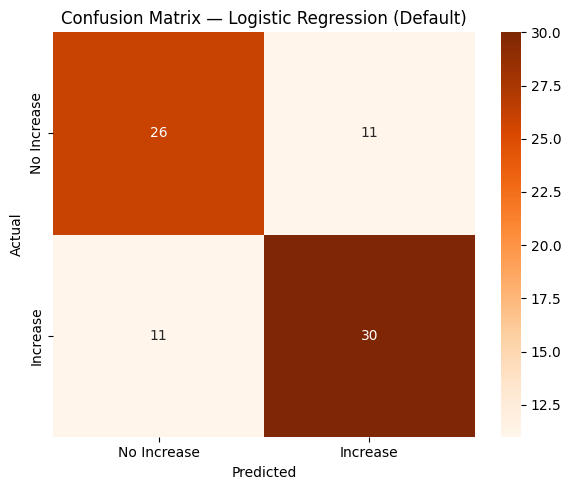


Model Comparison Table:

                 Model  Accuracy  Balanced Accuracy       AUC
0        Random Forest  0.564103           0.565590  0.651945
1        Decision Tree  0.525641           0.521094  0.521094
2    Gradient Boosting  0.487179           0.483191  0.471325
3  Logistic Regression  0.717949           0.717205  0.794990


In [ ]:
models = {
    "Random Forest": default_rf,
    "Decision Tree": default_dt,
    "Gradient Boosting": default_gb,
    "Logistic Regression": default_lr
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    auc_score = roc_auc_score(y_test, y_prob)

    results.append([name, acc, bal_acc, auc_score])

    print("\n====================")
    print(name)
    print("====================")
    print("Accuracy:", acc)
    print("Balanced Accuracy:", bal_acc)
    print("AUC:", auc_score)

    print(classification_report(y_test, y_pred))

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges",
                xticklabels=["No Increase", "Increase"],
                yticklabels=["No Increase", "Increase"])
    plt.title(f"Confusion Matrix — {name} (Default)")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()

# Comparison table
results_df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy", "Balanced Accuracy", "AUC"]
)

print("\nModel Comparison Table:\n")
print(results_df)


Built a 5-fold expanding-window cross-validation scheme by year: each fold trains
on all years up to a given point and validates on the next year, respecting the
chronological order of the data rather than shuffling years randomly.

Tuned all four candidate models — Random Forest, Decision Tree, Gradient
Boosting, and Logistic Regression — via `RandomizedSearchCV` over this year-based
CV, scoring by balanced accuracy. SMOTE was applied inside each fold through an
`imblearn` pipeline (rather than once upfront), so synthetic minority samples
were generated only from that fold's training years and never leaked into the
validation year.

For Logistic Regression, the `saga`-solver search space was split into an
`l1`/`l2` branch (no `l1_ratio`) and a separate `elasticnet`-only branch (with
`l1_ratio`), so `l1_ratio` was only ever sampled together with `penalty="elasticnet"`
— avoiding the sklearn warning that occurs when `l1_ratio` is supplied alongside a
non-elasticnet penalty.

In [ ]:
# ------------------------------------------------------------------
# 5-Fold expanding-window CV by year
# ------------------------------------------------------------------
train_years = sorted(data_clean.loc[train_mask, "Year"].unique())
n_folds = 5
val_start = len(train_years) - n_folds

year_cv = []
for i in range(val_start, len(train_years)):
    tr_years = train_years[:i]
    val_year = train_years[i]
    tr_idx = np.where(data_clean.loc[train_mask, "Year"].isin(tr_years))[0]
    val_idx = np.where(data_clean.loc[train_mask, "Year"] == val_year)[0]
    year_cv.append((tr_idx, val_idx))
    print(f"  Fold {len(year_cv)}: train {tr_years[0]}-{tr_years[-1]}, "
          f"val {val_year}  (train={len(tr_idx)}, val={len(val_idx)})")
print(f"Total CV folds: {len(year_cv)}")

n_iter = 300

# =========================
# Random Forest
# =========================
rf_pipe = ImbPipeline([
    ("smote", SMOTE(random_state=42, k_neighbors=3)),
    ("clf", RandomForestClassifier(random_state=42))
])

rf_grid = RandomizedSearchCV(
    rf_pipe,
    {
        "clf__n_estimators": randint(50, 800),
        "clf__max_depth": [3, 5, 7, 10, 15, 20, 30, None],
        "clf__min_samples_split": randint(2, 30),
        "clf__min_samples_leaf": randint(1, 15),
        "clf__max_features": ["sqrt", "log2", 0.3, 0.5, 0.7, 0.9, 1.0],
        "clf__bootstrap": [True, False],
        "clf__class_weight": ["balanced", "balanced_subsample", None]
    },
    n_iter=n_iter,
    cv=year_cv,
    scoring="balanced_accuracy",
    n_jobs=-1,
    random_state=42
)
rf_grid.fit(X_train, y_train)
best_rf = rf_grid.best_estimator_
print(f"RF best params: {rf_grid.best_params_}")
print(f"RF best CV balanced accuracy: {rf_grid.best_score_:.4f}")

# =========================
# Decision Tree
# =========================
dt_pipe = ImbPipeline([
    ("smote", SMOTE(random_state=42, k_neighbors=3)),
    ("clf", DecisionTreeClassifier(random_state=42))
])

dt_grid = RandomizedSearchCV(
    dt_pipe,
    {
        "clf__max_depth": [3, 5, 7, 10, 15, 20, 30, None],
        "clf__min_samples_split": randint(2, 30),
        "clf__min_samples_leaf": randint(1, 15),
        "clf__criterion": ["gini", "entropy", "log_loss"],
        "clf__max_features": ["sqrt", "log2", 0.3, 0.5, 0.7, 0.9, None],
        "clf__class_weight": ["balanced", None]
    },
    n_iter=n_iter,
    cv=year_cv,
    scoring="balanced_accuracy",
    n_jobs=-1,
    random_state=42
)
dt_grid.fit(X_train, y_train)
best_dt = dt_grid.best_estimator_
print(f"DT best params: {dt_grid.best_params_}")
print(f"DT best CV balanced accuracy: {dt_grid.best_score_:.4f}")

# =========================
# Gradient Boosting
# =========================
gb_pipe = ImbPipeline([
    ("smote", SMOTE(random_state=42, k_neighbors=3)),
    ("clf", GradientBoostingClassifier(random_state=42))
])

gb_grid = RandomizedSearchCV(
    gb_pipe,
    {
        "clf__n_estimators": randint(50, 800),
        "clf__learning_rate": uniform(0.005, 0.3),
        "clf__max_depth": [2, 3, 4, 5, 7, 10, 15],
        "clf__min_samples_split": randint(2, 30),
        "clf__min_samples_leaf": randint(1, 15),
        "clf__subsample": uniform(0.5, 0.5),
        "clf__max_features": ["sqrt", "log2", 0.3, 0.5, 0.7, 0.9],
        "clf__loss": ["log_loss", "exponential"]
    },
    n_iter=n_iter,
    cv=year_cv,
    scoring="balanced_accuracy",
    n_jobs=-1,
    random_state=42
)
gb_grid.fit(X_train, y_train)
best_gb = gb_grid.best_estimator_
print(f"GB best params: {gb_grid.best_params_}")
print(f"GB best CV balanced accuracy: {gb_grid.best_score_:.4f}")

# =========================
# Logistic Regression
# =========================
lr_pipe = ImbPipeline([
    ("smote", SMOTE(random_state=42, k_neighbors=3)),
    ("clf", LogisticRegression(random_state=42, max_iter=5000))
])

lr_param_dist = [
    {
        "clf__solver": ["liblinear"],
        "clf__penalty": ["l1", "l2"],
        "clf__C": loguniform(1e-3, 1e2),
        "clf__class_weight": ["balanced", None],
    },
    {
        "clf__solver": ["saga"],
        "clf__penalty": ["l1", "l2"],
        "clf__C": loguniform(1e-3, 1e2),
        "clf__class_weight": ["balanced", None],
    },
    {
        "clf__solver": ["saga"],
        "clf__penalty": ["elasticnet"],
        "clf__C": loguniform(1e-3, 1e2),
        "clf__l1_ratio": uniform(0, 1),  # only sampled when penalty == "elasticnet"
        "clf__class_weight": ["balanced", None],
    },
    {
        "clf__solver": ["lbfgs", "newton-cg"],
        "clf__penalty": ["l2"],
        "clf__C": loguniform(1e-3, 1e2),
        "clf__class_weight": ["balanced", None],
    },
]

lr_grid = RandomizedSearchCV(
    lr_pipe,
    lr_param_dist,
    n_iter=400,
    cv=year_cv,
    scoring="balanced_accuracy",
    n_jobs=-1,
    random_state=42
)
lr_grid.fit(X_train, y_train)
best_lr = lr_grid.best_estimator_
print(f"LR best params: {lr_grid.best_params_}")
print(f"LR best CV balanced accuracy: {lr_grid.best_score_:.4f}")

  Fold 1: train 2011-2016, val 2017  (train=192, val=36)
  Fold 2: train 2011-2017, val 2018  (train=228, val=37)
  Fold 3: train 2011-2018, val 2019  (train=265, val=38)
  Fold 4: train 2011-2019, val 2020  (train=303, val=39)
  Fold 5: train 2011-2020, val 2021  (train=342, val=39)
Total CV folds: 5
RF best params: {'clf__bootstrap': True, 'clf__class_weight': None, 'clf__max_depth': 15, 'clf__max_features': 0.5, 'clf__min_samples_leaf': 6, 'clf__min_samples_split': 8, 'clf__n_estimators': 140}
RF best CV balanced accuracy: 0.6261
DT best params: {'clf__class_weight': 'balanced', 'clf__criterion': 'log_loss', 'clf__max_depth': 3, 'clf__max_features': 0.7, 'clf__min_samples_leaf': 4, 'clf__min_samples_split': 5}
DT best CV balanced accuracy: 0.6175
GB best params: {'clf__learning_rate': np.float64(0.011655422609090488), 'clf__loss': 'exponential', 'clf__max_depth': 3, 'clf__max_features': 0.9, 'clf__min_samples_leaf': 6, 'clf__min_samples_split': 4, 'clf__n_estimators': 355, 'clf__sub

Evaluated the tuned models (selected via the cross-validated search in the
previous cell) on the held-out test set, using accuracy, balanced accuracy,
ROC-AUC, and full classification reports. Compiled the results into a comparison
table to measure against the default-model baseline.

In [ ]:
models = {
    "Random Forest": best_rf,
    "Decision Tree": best_dt,
    "Gradient Boosting": best_gb,
    "Logistic Regression": best_lr
}

results = []

for name, model in models.items():
    # model is already fitted inside the pipeline from Cell 21's
    # RandomizedSearchCV(refit=True) — do NOT call .fit() again here.

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    auc_score = roc_auc_score(y_test, y_prob)

    results.append([name, acc, bal_acc, auc_score])

    print("\n====================")
    print(name)
    print("====================")
    print("Accuracy:", acc)
    print("Balanced Accuracy:", bal_acc)
    print("AUC:", auc_score)

    print(classification_report(y_test, y_pred))

results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Balanced Accuracy", "AUC"])
print("\nModel Comparison Table:\n")
print(results_df)


Random Forest
Accuracy: 0.5769230769230769
Balanced Accuracy: 0.5856954515491101
AUC: 0.6704021094264996
              precision    recall  f1-score   support

           0       0.54      0.76      0.63        37
           1       0.65      0.41      0.51        41

    accuracy                           0.58        78
   macro avg       0.60      0.59      0.57        78
weighted avg       0.60      0.58      0.57        78


Decision Tree
Accuracy: 0.6153846153846154
Balanced Accuracy: 0.6275543836519446
AUC: 0.6529334212261042
              precision    recall  f1-score   support

           0       0.56      0.86      0.68        37
           1       0.76      0.39      0.52        41

    accuracy                           0.62        78
   macro avg       0.66      0.63      0.60        78
weighted avg       0.67      0.62      0.59        78


Gradient Boosting
Accuracy: 0.5512820512820513
Balanced Accuracy: 0.5520764667106131
AUC: 0.59887936717205
              precision   

Plotted ROC curves for all tuned models on the test set to visually compare
their discrimination ability against each other and against a random-guess
baseline (the diagonal reference line).

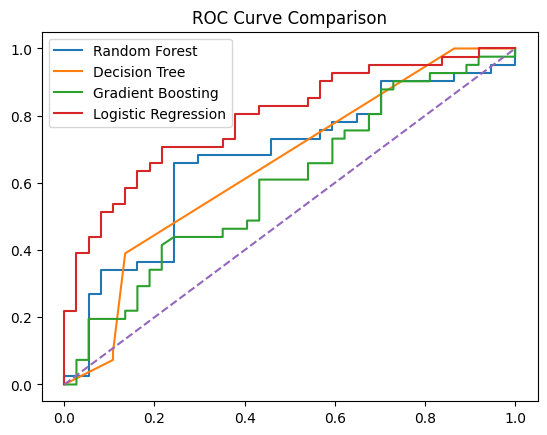

In [ ]:
plt.figure()

for name, model in models.items():
    y_prob = model.predict_proba(X_test)[:,1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, label=name)

plt.plot([0,1],[0,1],'--')
plt.legend()
plt.title("ROC Curve Comparison")
plt.show()


Plotted confusion matrices for each tuned model to inspect the trade-off between
false positives and false negatives, complementing the aggregate metrics and ROC
curves shown above.

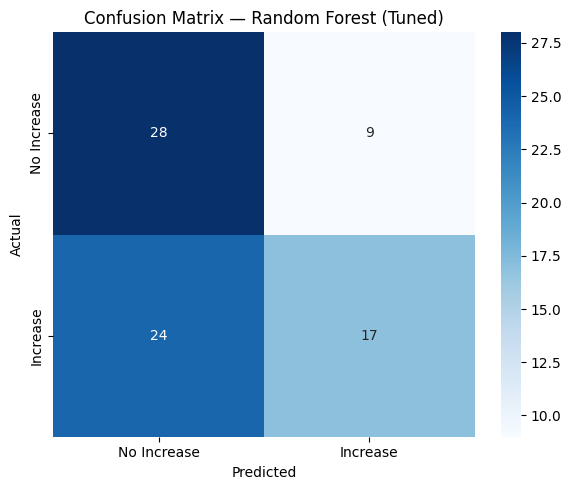

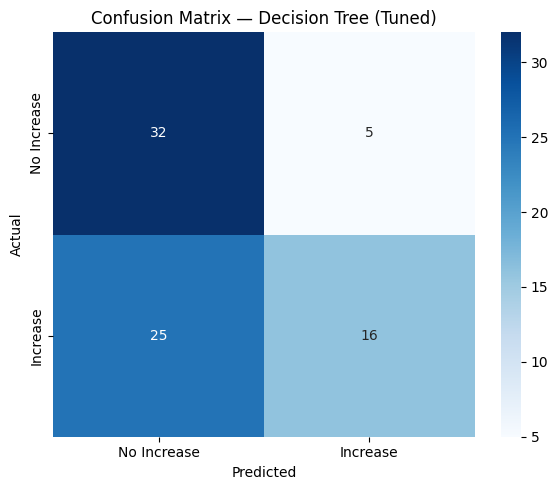

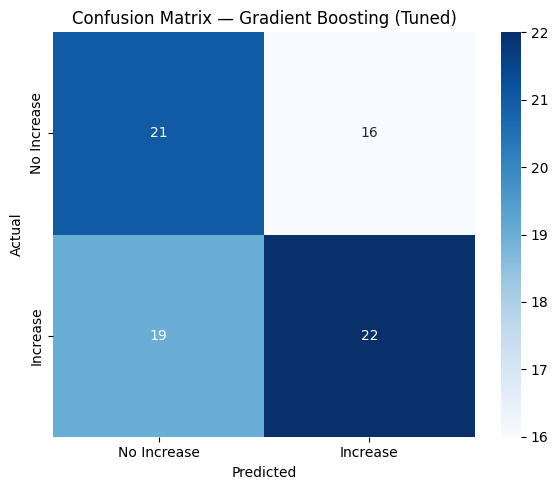

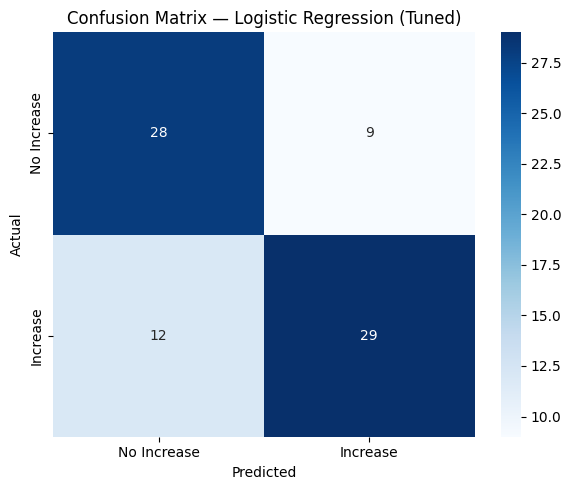

In [ ]:
tuned_models_dict = {
    "Random Forest (Tuned)": best_rf,
    "Decision Tree (Tuned)": best_dt,
    "Gradient Boosting (Tuned)": best_gb,
    "Logistic Regression (Tuned)": best_lr
}

for name, model in tuned_models_dict.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["No Increase", "Increase"],
                yticklabels=["No Increase", "Increase"])
    plt.title(f"Confusion Matrix — {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()


## 6. Model Selection

Computed cross-validated balanced accuracy for both tuned candidates (already
available from `RandomizedSearchCV.best_score_`) and default candidates
(scored fresh with `cross_val_score`, using the same `year_cv` folds and with
SMOTE applied inside each fold via an `imblearn` pipeline). This kept the
comparison on a consistent, leakage-free footing across all eight candidates.

Compiled a full comparison table of CV balanced accuracy, test-set accuracy,
balanced accuracy, AUC, and per-class F1 for all default and tuned models.
CV balanced accuracy was treated as the primary, unbiased selection metric,
with test-set metrics reported only for transparency and not used to choose
the best model.

In [ ]:
from sklearn.model_selection import cross_val_score

cv_scores = {
    "RF (Tuned)":  rf_grid.best_score_,
    "DT (Tuned)":  dt_grid.best_score_,
    "GB (Tuned)":  gb_grid.best_score_,
    "LR (Tuned)":  lr_grid.best_score_,
}

# FIX: default models scored with SMOTE inside each fold via an
# imblearn Pipeline, evaluated on X_train/y_train — consistent index
# space with year_cv, avoiding the X_train_bal mismatch.
default_pipelines_for_cv = {
    "RF (Default)": ImbPipeline([
        ("smote", SMOTE(random_state=42, k_neighbors=3)),
        ("clf", RandomForestClassifier(random_state=42))
    ]),
    "DT (Default)": ImbPipeline([
        ("smote", SMOTE(random_state=42, k_neighbors=3)),
        ("clf", DecisionTreeClassifier(random_state=42))
    ]),
    "GB (Default)": ImbPipeline([
        ("smote", SMOTE(random_state=42, k_neighbors=3)),
        ("clf", GradientBoostingClassifier(random_state=42))
    ]),
    "LR (Default)": ImbPipeline([
        ("smote", SMOTE(random_state=42, k_neighbors=3)),
        ("clf", LogisticRegression(random_state=42, max_iter=1000))
    ])
}
for label, pipe in default_pipelines_for_cv.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=year_cv, scoring="balanced_accuracy")
    cv_scores[label] = scores.mean()

print("CV Balanced Accuracy (all candidates):")
for name, score in sorted(cv_scores.items(), key=lambda x: -x[1]):
    print(f"  {name:25s}  {score:.4f}")

# ------------------------------------------------------------------
# DEFAULT vs TUNED MODEL COMPARISON
# NOTE: CV bal. acc. is the UNBIASED selection metric.
#       Test metrics are reported for transparency but were NOT
#       used to pick the best model.
# ------------------------------------------------------------------
all_compare = {
    "RF (Default)": default_models["Random Forest (Default)"],
    "RF (Tuned)": best_rf,
    "DT (Default)": default_models["Decision Tree (Default)"],
    "DT (Tuned)": best_dt,
    "GB (Default)": default_models["Gradient Boosting (Default)"],
    "GB (Tuned)": best_gb,
    "LR (Default)": default_lr,
    "LR (Tuned)": best_lr
}

comparison = []
for name, model in all_compare.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    acc = accuracy_score(y_test, y_pred)
    bal_acc = balanced_accuracy_score(y_test, y_pred)
    auc_val = roc_auc_score(y_test, y_prob)
    cr = classification_report(y_test, y_pred, output_dict=True)
    f1_0 = cr["0"]["f1-score"]
    f1_1 = cr["1"]["f1-score"]
    comparison.append({
        "Model": name,
        "CV Bal. Acc.": round(cv_scores[name], 4),
        "Test Acc.": round(acc, 4),
        "Test Bal. Acc.": round(bal_acc, 4),
        "Test AUC": round(auc_val, 4),
        "F1 (Class 0)": round(f1_0, 4),
        "F1 (Class 1)": round(f1_1, 4)
    })

comp_df = pd.DataFrame(comparison)
print("DEFAULT vs TUNED MODEL COMPARISON")
print("=" * 120)
print("Selection metric: CV Balanced Accuracy (unbiased)")
print("Test metrics shown for transparency only.")
print()
print(comp_df.to_string(index=False))

CV Balanced Accuracy (all candidates):
  LR (Tuned)                 0.6273
  RF (Tuned)                 0.6261
  DT (Tuned)                 0.6175
  GB (Tuned)                 0.6171
  LR (Default)               0.5984
  GB (Default)               0.5632
  RF (Default)               0.5596
  DT (Default)               0.5339
DEFAULT vs TUNED MODEL COMPARISON
Selection metric: CV Balanced Accuracy (unbiased)
Test metrics shown for transparency only.

       Model  CV Bal. Acc.  Test Acc.  Test Bal. Acc.  Test AUC  F1 (Class 0)  F1 (Class 1)
RF (Default)        0.5596     0.5641          0.5656    0.6519        0.5641        0.5641
  RF (Tuned)        0.6261     0.5769          0.5857    0.6704        0.6292        0.5075
DT (Default)        0.5339     0.5256          0.5211    0.5211        0.4638        0.5747
  DT (Tuned)        0.6175     0.6154          0.6276    0.6529        0.6809        0.5161
GB (Default)        0.5632     0.4872          0.4832    0.4713        0.4286        0

Persisted all eight candidate models (four tuned pipelines, four default
estimators) to disk individually, then dynamically selected `best_model` as
whichever candidate had the highest CV balanced accuracy from the previous cell
— with no hardcoded winner. Saved the selected model separately as the primary
`dividend_prediction_model.pkl`, along with the held-out test set
(`dividend_test_dataset.csv`) for later reuse.

In [ ]:
# ------------------------------------------------------------------
# Save all candidate models and pick the primary one DYNAMICALLY by
# CV balanced accuracy (cv_scores, computed in Cell 25) across BOTH
# default and tuned candidates -- no hardcoding.
#
# Tuned models are ImbPipelines (SMOTE+clf).
# Default models are bare estimators trained on SMOTE-resampled
# raw (unscaled) features.
# ------------------------------------------------------------------
import joblib

# Save all tuned pipelines
joblib.dump(best_rf, "dividend_prediction_model_rf_tuned.pkl")
joblib.dump(best_dt, "dividend_prediction_model_dt_tuned.pkl")
joblib.dump(best_gb, "dividend_prediction_model_gb_tuned.pkl")
joblib.dump(best_lr, "dividend_prediction_model_lr_tuned.pkl")

# Save all default models
joblib.dump(default_rf, "dividend_prediction_model_rf_default.pkl")
joblib.dump(default_dt, "dividend_prediction_model_dt_default.pkl")
joblib.dump(default_gb, "dividend_prediction_model_gb_default.pkl")
joblib.dump(default_lr, "dividend_prediction_model_lr_default.pkl")

# Map each cv_scores name -> (fitted model object, X_test)
candidates = {
    "RF (Tuned)":   (best_rf,     X_test),
    "DT (Tuned)":   (best_dt,     X_test),
    "GB (Tuned)":   (best_gb,     X_test),
    "LR (Tuned)":   (best_lr,     X_test),
    "RF (Default)": (default_rf,  X_test),
    "DT (Default)": (default_dt,  X_test),
    "GB (Default)": (default_gb,  X_test),
    "LR (Default)": (default_lr,  X_test),
}

# Pick the winner purely from CV balanced accuracy across ALL 8 candidates
best_model_name = max(cv_scores, key=cv_scores.get)
best_model, _ = candidates[best_model_name]

print("CV Balanced Accuracy (all candidates):")
for name, score in sorted(cv_scores.items(), key=lambda x: -x[1]):
    marker = "  <-- selected" if name == best_model_name else ""
    print(f"  {name:15s}  {score:.4f}{marker}")

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print(f"\nPrimary model: {best_model_name}")
print(f"Held-out test bal. acc.: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Held-out test AUC:       {roc_auc_score(y_test, y_prob):.4f}")

# Save primary model for export
joblib.dump(best_model, "dividend_prediction_model.pkl")

test_dataset = X_test.copy()
test_dataset["Target"] = y_test
test_dataset.to_csv("dividend_test_dataset.csv", index=False)

model_type = (
    type(best_model.named_steps["clf"]).__name__
    if hasattr(best_model, "named_steps")
    else type(best_model).__name__
)
print(f"\nSaved files:")
print(f"  dividend_prediction_model.pkl             ({best_model_name} - primary, clf type: {model_type})")
print(f"  dividend_prediction_model_rf_tuned.pkl")
print(f"  dividend_prediction_model_dt_tuned.pkl")
print(f"  dividend_prediction_model_gb_tuned.pkl")
print(f"  dividend_prediction_model_lr_tuned.pkl")
print(f"  dividend_prediction_model_rf_default.pkl")
print(f"  dividend_prediction_model_dt_default.pkl")
print(f"  dividend_prediction_model_gb_default.pkl")
print(f"  dividend_prediction_model_lr_default.pkl")
print(f"  dividend_test_dataset.csv")

CV Balanced Accuracy (all candidates):
  LR (Tuned)       0.6273  <-- selected
  RF (Tuned)       0.6261
  DT (Tuned)       0.6175
  GB (Tuned)       0.6171
  LR (Default)     0.5984
  GB (Default)     0.5632
  RF (Default)     0.5596
  DT (Default)     0.5339

Primary model: LR (Tuned)
Held-out test bal. acc.: 0.7320
Held-out test AUC:       0.7930

Saved files:
  dividend_prediction_model.pkl             (LR (Tuned) - primary, clf type: LogisticRegression)
  dividend_prediction_model_rf_tuned.pkl
  dividend_prediction_model_dt_tuned.pkl
  dividend_prediction_model_gb_tuned.pkl
  dividend_prediction_model_lr_tuned.pkl
  dividend_prediction_model_rf_default.pkl
  dividend_prediction_model_dt_default.pkl
  dividend_prediction_model_gb_default.pkl
  dividend_prediction_model_lr_default.pkl
  dividend_test_dataset.csv


Ran a systematic set of data-leakage checks on the final setup: confirmed no
year overlap between train and test sets, confirmed no dividend- or
target-related terms among the feature columns, confirmed SMOTE was applied
only to the training data, compared feature distributions between train and
test for consistency, confirmed no residual `Dividend_Change` column existed in
the dataset, and confirmed the target was built from a genuine T+1 shift rather
than a same-year value.

In [ ]:
print("DATA LEAKAGE CHECK")
print("=" * 60)

# 1. Check train/test year overlap
train_years = set(data_clean.loc[train_mask, "Year"].unique())
test_years = set(data_clean.loc[test_mask, "Year"].unique())
overlap = train_years & test_years
print(f"\n1. Train year range: {min(train_years)} - {max(train_years)}")
print(f"   Test year range:  {min(test_years)} - {max(test_years)}")
if overlap:
    print(f"   WARNING: Year overlap detected: {sorted(overlap)}")
else:
    print(f"   OK: No year overlap between train and test.")

# 2. Check for target leakage in features
print(f"\n2. Feature columns used: {features}")
leakage_keywords = ["dividend", "next", "target", "change"]
found_leak = False
for f in features:
    for kw in leakage_keywords:
        if kw in f.lower():
            print(f"   WARNING: Feature '{f}' may contain leakage (matches '{kw}')")
            found_leak = True
if not found_leak:
    print("   OK: No dividend or target-related columns in features.")

# 3. Check SMOTE was applied only to training data
print(f"\n3. SMOTE applied to: X_train only (shape {X_train.shape})")
print(f"   Test set untouched (shape {X_test.shape})")
print("   OK: SMOTE not applied to test set.")

# 4. Check feature statistics between train and test
print(f"\n4. Feature distribution comparison (train vs test):")
for f in features:
    train_mean = X_train[f].mean()
    test_mean = X_test[f].mean()
    diff = abs(train_mean - test_mean)
    status = "OK" if diff < 0.5 else "CHECK"
    print(f"   {f}: train_mean={train_mean:.4f}, test_mean={test_mean:.4f}, diff={diff:.4f} [{status}]")

# 5. Check Dividend_Change not in data
print(f"\n5. Checking for Dividend_Change column...")
if "Dividend_Change" in data_clean.columns:
    print("   WARNING: Dividend_Change column exists in dataset!")
else:
    print("   OK: Dividend_Change not present in dataset.")

# 6. Check no same-year prediction
print(f"\n6. Checking prediction direction (genuine future prediction)...")
print("   Target = 1 if Next_Year_Dividend > Current_Dividend")
print("   OK: Target uses shifted dividend (year t+1 vs year t).")

print(f"\n{'=' * 60}")
print("LEAKAGE CHECK COMPLETE")


DATA LEAKAGE CHECK

1. Train year range: 2011 - 2021
   Test year range:  2022 - 2023
   OK: No year overlap between train and test.

2. Feature columns used: ['Price_Momentum', 'Price_Range_Ratio', 'Volume_Momentum']
   OK: No dividend or target-related columns in features.

3. SMOTE applied to: X_train only (shape (381, 3))
   Test set untouched (shape (78, 3))
   OK: SMOTE not applied to test set.

4. Feature distribution comparison (train vs test):
   Price_Momentum: train_mean=0.3197, test_mean=0.1733, diff=0.1463 [OK]
   Price_Range_Ratio: train_mean=1.8063, test_mean=1.9855, diff=0.1793 [OK]
   Volume_Momentum: train_mean=0.0660, test_mean=0.0565, diff=0.0095 [OK]

5. Checking for Dividend_Change column...
   OK: Dividend_Change not present in dataset.

6. Checking prediction direction (genuine future prediction)...
   Target = 1 if Next_Year_Dividend > Current_Dividend
   OK: Target uses shifted dividend (year t+1 vs year t).

LEAKAGE CHECK COMPLETE


## 7. SHAP Interpretation

Extracted the underlying classifier from `best_model` (handling both plain
estimators and sklearn/imblearn pipelines) and built a SHAP explainer on the
training data to explain its predictions on the test set.

Normalised the SHAP output across the different shapes SHAP can return
(binary vs. multiclass, list vs. array, with or without a class dimension) into
a single per-feature importance array, with a safety check to confirm the
importance count matched the number of features.

Computed mean absolute SHAP values per feature, ranked them, and plotted them as
a horizontal bar chart alongside a summary table — showing which of the three
engineered features contributed most to the selected model's dividend-increase
predictions.

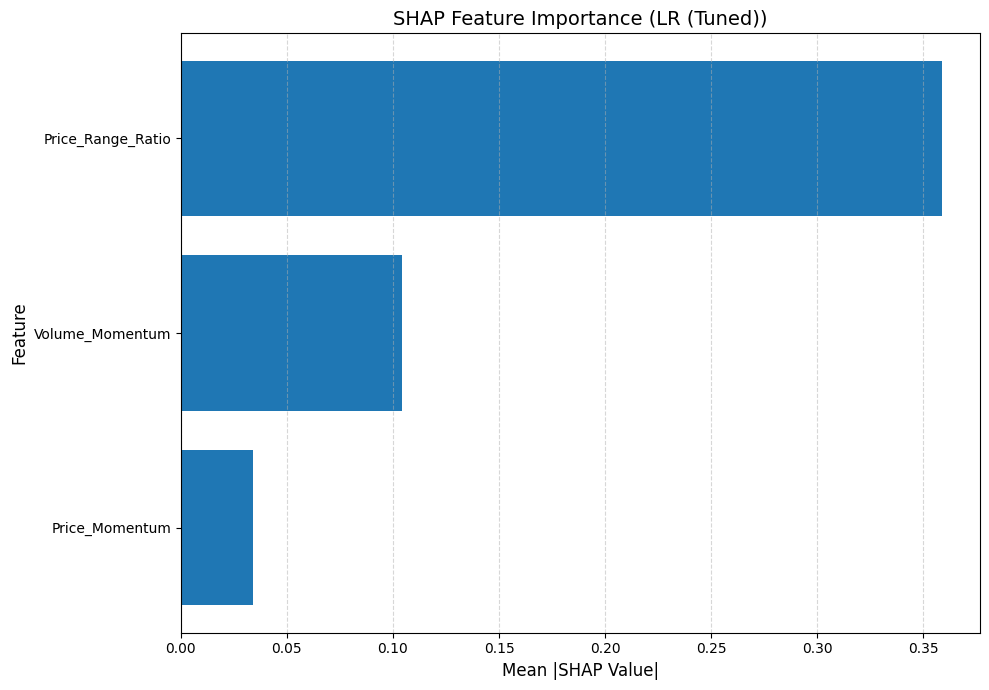

,Feature,Importance
1,Price_Range_Ratio,0.358722
2,Volume_Momentum,0.104266
0,Price_Momentum,0.034035


In [ ]:
# FIX: best_model can now be either an sklearn or imblearn Pipeline
shap_model = best_model.named_steps["clf"] if isinstance(best_model, (SkPipeline, ImbPipeline)) else best_model


explainer = shap.Explainer(shap_model, X_train)
shap_explanation = explainer(X_test)
shap_values = shap_explanation.values

# Convert to numpy array if needed
if isinstance(shap_values, list):
    # Older SHAP versions
    if len(shap_values) == 2:
        # Binary classification -> positive class
        shap_values = shap_values[1]
    else:
        # Multiclass -> average over classes
        shap_values = np.mean(np.abs(np.array(shap_values)), axis=0)
else:
    shap_values = np.array(shap_values)

# Handle different output shapes
if shap_values.ndim == 3:
    # Shape could be (samples, features, classes)
    if shap_values.shape[2] == 2:
        shap_values = shap_values[:, :, 1]
    else:
        shap_values = np.mean(np.abs(shap_values), axis=2)

elif shap_values.ndim == 1:
    shap_values = shap_values.reshape(-1, 1)

# Compute mean absolute SHAP importance
importance = np.abs(shap_values).mean(axis=0)

# Flatten if still not 1D
importance = np.ravel(importance)

# Safety check
if len(importance) != len(X_test.columns):
    raise ValueError(
        f"Number of SHAP importances ({len(importance)}) "
        f"does not match number of features ({len(X_test.columns)}).\n"
        f"SHAP shape: {np.array(shap_values).shape}"
    )

# Create dataframe
feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance
}).sort_values(by="Importance", ascending=False)

# Plot
plt.figure(figsize=(10, 7))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)
plt.gca().invert_yaxis()
plt.xlabel("Mean |SHAP Value|", fontsize=12)
plt.ylabel("Feature", fontsize=12)
plt.title(f"SHAP Feature Importance ({best_model_name})", fontsize=14)
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

# Display feature importance table
display(feature_importance)

Reloaded the saved primary model (`dividend_prediction_model.pkl`) and the saved
test set (`dividend_test_dataset.csv`) from disk, and re-ran predictions on them
independently of the earlier in-notebook evaluation. Compared predicted vs.
actual outcomes row by row and summarised overall correct/incorrect counts,
confirming the persisted model artifact reproduces the expected results.

In [ ]:
loaded_model = joblib.load("dividend_prediction_model.pkl")
test_data = pd.read_csv("dividend_test_dataset.csv")

features = ["Price_Momentum", "Price_Range_Ratio", "Volume_Momentum"]
X_loaded = test_data[features]
y_actual = test_data["Target"]

y_predicted = loaded_model.predict(X_loaded)

results = test_data[["Price_Momentum", "Price_Range_Ratio", "Volume_Momentum"]].copy()
results["Actual"] = y_actual.values
results["Predicted"] = y_predicted
results["Correct"] = results["Actual"] == results["Predicted"]

print("PREDICTION RESULTS (Loaded Model vs Test Set)")
print("=" * 60)
print(results.to_string(index=True))
print(f"\nTotal: {len(results)} | Correct: {results['Correct'].sum()} | Incorrect: {(~results['Correct']).sum()}")



PREDICTION RESULTS (Loaded Model vs Test Set)
    Price_Momentum  Price_Range_Ratio  Volume_Momentum  Actual  Predicted  Correct
0        -0.264042           1.445018        -0.032733       1          1     True
1        -0.406535           2.092964         0.493830       0          0     True
2        -0.049123           1.354144         0.026685       1          1     True
3        -0.375426           2.333074        -0.020392       1          0    False
4        -0.549896           2.793110         0.776620       0          0     True
5        -0.132697           1.582091         0.258412       1          1     True
6        -0.137966           1.473473         0.191324       0          1    False
7        -0.478259           2.033165         0.240847       0          0     True
8        -0.485763           2.451874         0.186404       0          0     True
9        -0.224628           1.591245         0.099221       1          1     True
10       -0.266330           1.843216    